# Predicting 30-day hospital readmission

Can discharge-time data flag the diabetic inpatients most likely to return within 30 days? This notebook walks through the analysis implemented in `modeling.py` on the UCI Diabetes 130-US Hospitals data (101,766 encounters, 1999 to 2008).

Design: encounters ending in death or hospice are excluded, the data are split 60/20/20 **by patient**, a logistic regression and a gradient-boosted model are tuned and compared on the validation patients only, and the test patients are scored once.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from modeling import run_analysis

pd.set_option("display.precision", 3)
summary = run_analysis(Path("data") / "diabetic_data.csv.gz")
pd.Series({**summary["data"], **summary["split"]})

source_rows                                                             101766
rows_after_eligibility                                                   99343
patients                                                                 69990
share_of_patients_with_repeat_encounters                                 0.233
share_of_encounters_from_repeat_patients                                  0.46
target_prevalence                                                        0.114
prediction_timestamp                        end of index encounter (discharge)
train_rows                                                               59565
validation_rows                                                          19917
test_rows                                                                19861
train_patients                                                           41994
validation_patients                                                      13998
test_patients                                       

## Model selection (validation patients only)

Each candidate is fit on the training patients and scored on the validation patients. The model with the highest validation ROC-AUC is selected before the test set is touched.

In [2]:
pd.read_csv("metrics/model_selection.csv")

,model,params,roc_auc,pr_auc,brier,log_loss
0,logistic_regression,"{""C"": 0.01}",0.660,0.212,0.097,0.337
1,logistic_regression,"{""C"": 0.1}",0.661,0.215,0.097,0.336
2,logistic_regression,"{""C"": 1.0}",0.660,0.214,0.097,0.336
3,gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 300, ""max_...",0.673,0.233,0.096,0.333
4,gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 500, ""max_...",0.673,0.235,0.096,0.333
5,gradient_boosting,"{""learning_rate"": 0.03, ""max_iter"": 800, ""max_...",0.674,0.235,0.095,0.332
6,gradient_boosting,"{""learning_rate"": 0.03, ""max_iter"": 400, ""max_...",0.675,0.237,0.095,0.332


## Held-out test performance

ROC-AUC and PR-AUC measure ranking; Brier score and log loss measure probability accuracy. Intervals come from a patient-cluster bootstrap (whole patients resampled with replacement).

In [3]:
ci = summary["uncertainty_95pct"]
rows = []
for name, metrics in summary["test"].items():
    row = {"model": name, **metrics}
    if name in ci:
        row["roc_auc_95ci"] = f"{ci[name]['roc_auc']['low_2.5']:.3f} to {ci[name]['roc_auc']['high_97.5']:.3f}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("model"))
diff = ci["roc_auc_difference_gradient_boosting_minus_logistic_regression"]
print(f"Paired ROC-AUC gain, boosting minus logistic: {diff['low_2.5']:.3f} to {diff['high_97.5']:.3f} (95% CI)")

,roc_auc,pr_auc,brier,log_loss,roc_auc_95ci
model,,,,,
prevalence_baseline,0.500,0.113,0.101,0.354,NaN
logistic_regression,0.664,0.215,0.096,0.335,0.650 to 0.679
gradient_boosting,0.675,0.235,0.095,0.332,0.662 to 0.691


Paired ROC-AUC gain, boosting minus logistic: 0.007 to 0.017 (95% CI)


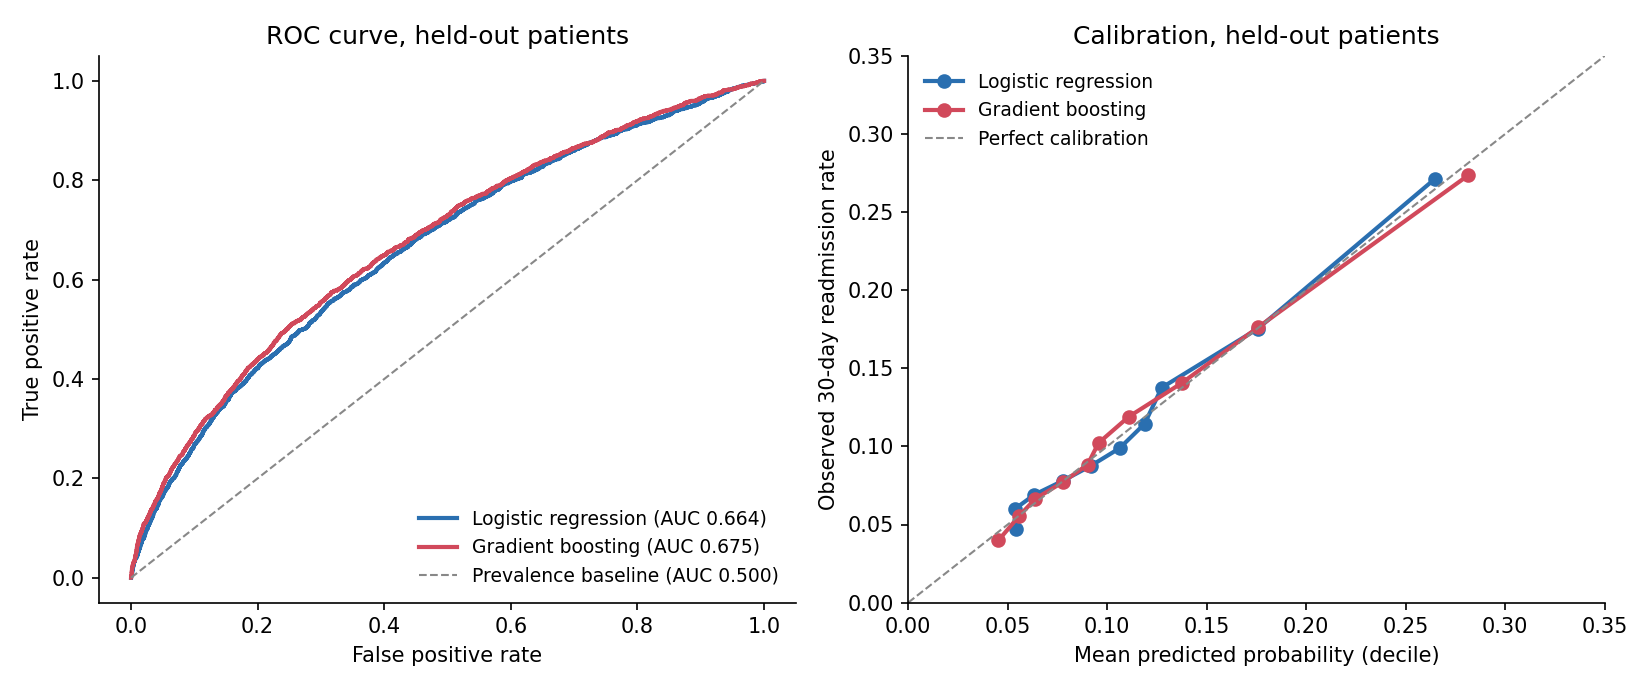

,intercept,slope
logistic_regression,-0.060,0.972
gradient_boosting,0.028,1.018


In [4]:
display(Image("figures/roc_calibration.png"))
pd.DataFrame(summary["calibration_intercept_slope"]).T

## Operating points

A care-management team can only call so many patients. The score cutoff for each flag rate is set on the validation patients and applied unchanged to the test patients.

In [5]:
pd.read_csv("metrics/threshold_metrics.csv")

,target_flag_rate,score_cutoff,test_flag_rate,precision,recall,lift_over_prevalence
0,0.05,0.242,0.053,0.334,0.156,2.943
1,0.10,0.198,0.106,0.279,0.260,2.457
2,0.20,0.154,0.204,0.228,0.409,2.009
3,0.30,0.128,0.302,0.197,0.525,1.739


## Subgroup diagnostics

Discrimination and calibration-in-the-large (observed rate vs. mean predicted risk) by gender, race and age band, for groups with at least 200 test encounters.

In [6]:
pd.read_csv("metrics/subgroup_metrics.csv")

,feature,group,n,observed_rate,mean_predicted,roc_auc,pr_auc
0,gender,Female,10804,0.113,0.116,0.679,0.238
1,gender,Male,9057,0.114,0.111,0.670,0.233
2,race,AfricanAmerican,3927,0.116,0.119,0.672,0.255
3,race,Caucasian,14670,0.115,0.114,0.674,0.234
4,race,Hispanic,396,0.076,0.100,0.770,0.168
5,race,Missing,449,0.098,0.077,0.684,0.224
6,race,Other,286,0.087,0.105,0.692,0.228
7,age,[20-30),369,0.171,0.159,0.786,0.439
8,age,[30-40),764,0.101,0.114,0.711,0.222
9,age,[40-50),1873,0.104,0.105,0.714,0.271


## What drives the predictions

Permutation importance on the validation patients: how much ROC-AUC drops when one input column is shuffled. These are predictive signals, not causal effects.

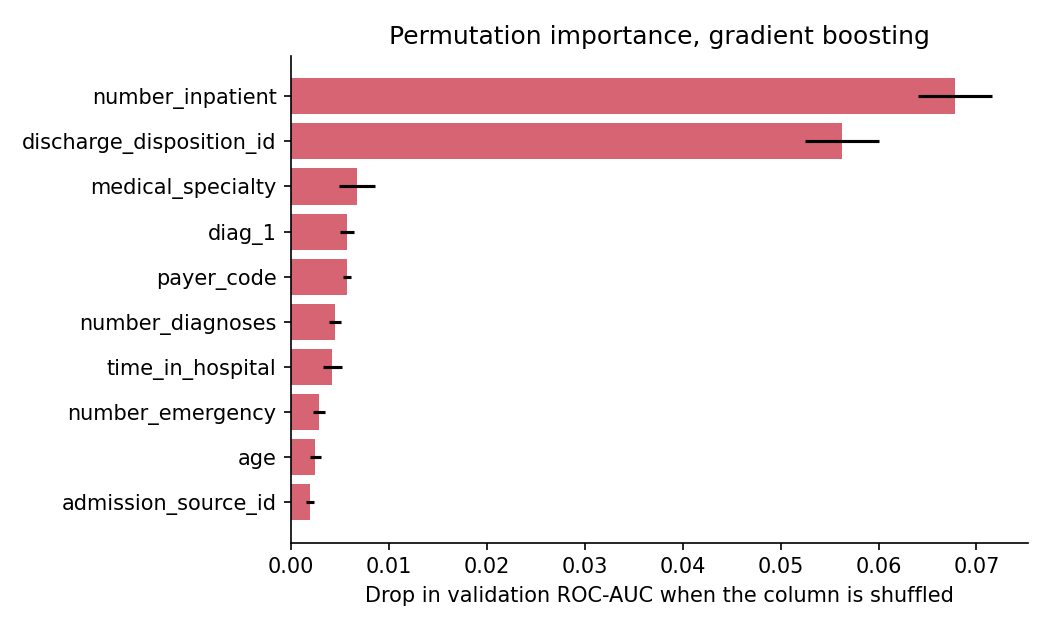

,feature,roc_auc_drop_mean,roc_auc_drop_std
0,number_inpatient,0.068,3.805e-03
1,discharge_disposition_id,0.056,3.773e-03
2,medical_specialty,0.007,1.820e-03
3,diag_1,0.006,6.752e-04
4,payer_code,0.006,4.144e-04
5,number_diagnoses,0.004,6.435e-04
6,time_in_hospital,0.004,1.006e-03
7,number_emergency,0.003,5.923e-04
8,age,0.002,5.644e-04
9,admission_source_id,0.002,4.161e-04


In [7]:
display(Image("figures/permutation_importance.png"))
pd.read_csv("metrics/permutation_importance.csv").head(10)

## Takeaways

* Prior inpatient use and discharge disposition carry most of the signal. Diagnoses, specialty and payer add a little.
* Gradient boosting beats logistic regression by a small but consistent margin, and both are well calibrated on held-out patients.
* Discrimination is modest. That ceiling is typical for administrative data without labs, vitals, social factors or post-discharge information.